In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [20]:
# data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
# !wget $data -O course_lead_scoring_2026.csv

In [89]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [90]:
df.head(n=100).T

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
lead_source,organic_search,social_media,referral,paid_ads,referral,referral,NaN,paid_ads,organic_search,referral,...,organic_search,referral,organic_search,paid_ads,referral,paid_ads,referral,events,organic_search,events
industry,technology,technology,retail,manufacturing,manufacturing,manufacturing,education,technology,healthcare,retail,...,technology,education,finance,technology,education,retail,finance,technology,technology,retail
employment_status,employed,employed,employed,student,student,employed,employed,employed,employed,student,...,unemployed,self_employed,employed,unemployed,student,unemployed,employed,unemployed,employed,self_employed
location,europe,south_america,europe,NaN,north_america,africa,north_america,north_america,asia,asia,...,europe,europe,south_america,europe,africa,asia,asia,europe,europe,africa
annual_income,88160.0,72688.0,44697.0,NaN,24062.0,43841.0,58738.0,95059.0,62565.0,12000.0,...,53767.0,43499.0,59780.0,51151.0,NaN,21084.0,75202.0,50096.0,95649.0,34621.0
number_of_courses_viewed,3,3,3,3,4,3,3,2,3,2,...,3,1,2,1,3,4,2,1,1,2
interaction_count,4,7,4,6,5,5,9,4,6,2,...,5,8,4,5,3,9,5,0,1,4
lead_score,0.64,0.72,0.58,0.57,0.62,0.77,0.78,0.41,0.52,0.35,...,0.46,0.63,0.43,0.49,0.37,0.68,0.59,0.18,0.37,0.5
converted,1,1,1,0,1,1,1,1,1,0,...,0,1,0,0,0,1,1,0,1,1


In [91]:
df.columns.str.lower()

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [92]:
# df.columns = df.columns.str.lower().str.replace(' ', '_')

# categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

# for c in categorical_columns:
#     df[c] = df[c].str.lower().str.replace(' ', '_')

In [93]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [94]:
for c in categorical:
    df[c] = df[c].str.lower().str.replace(' ', '_')
    df[c] = df[c].fillna('NA')
    print(df[c].isna().sum())

0
0
0
0


In [95]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [96]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
for col in numerical:
    print(df[col].isna().sum())


369
0
0
35


In [97]:
df['lead_score'].isna().sum()

np.int64(35)

In [98]:
df['annual_income'] = df['annual_income'].fillna(0)

In [99]:
df['lead_score'] = df['lead_score'].fillna(0)

In [100]:
df.head(n=50)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
5,referral,manufacturing,employed,africa,43841.0,3,5,0.77,1
6,NA,education,employed,north_america,58738.0,3,9,0.78,1
7,paid_ads,technology,employed,north_america,95059.0,2,4,0.41,1
8,organic_search,healthcare,employed,asia,62565.0,3,6,0.52,1
9,referral,retail,student,asia,12000.0,2,2,0.35,0


In [101]:
from sklearn.model_selection import train_test_split
# split the data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [102]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [103]:
# EDA
# Use the training and validation dataset together
df_full_train = df_full_train.reset_index(drop=True)

In [104]:
# EDA - look at the target variable 'converted'
df_full_train.converted.value_counts(normalize=True)

converted
1    0.57875
0    0.42125
Name: proportion, dtype: float64

In [105]:
# extract the target variable or `converted` column
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [106]:
del df_train['converted']
# del df_full_train['converted']
del df_val['converted']
del df_test['converted']

In [107]:
# Q1: Question 1: ROC AUC feature importance
from sklearn.metrics import roc_auc_score
# --> lead score
roc_auc_score(y_train, df_train['lead_score'])

0.7882254810906102

In [108]:
# numerical variable: number_of_courses_viewed
roc_auc_score(y_train, df_train['number_of_courses_viewed'])

0.7229894623989618

In [109]:
# numerical variable: interaction_count
roc_auc_score(y_train, df_train['interaction_count'])

0.7649203047563227

In [110]:
# numerical variable: annual_income
roc_auc_score(y_train, df_train['annual_income'])

0.6081977776250831

In [111]:
# Q2: Training the model
# One-hot encode the categorical columns into multiple binary columns
dicts = df[categorical + numerical].to_dict(orient='records')

from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)
all_categories = categorical + numerical
all_categories

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

# get the names of all the columns
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [112]:
X_train.shape


(3000, 28)

In [113]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [114]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]

In [115]:
# compute the ROC curve and area in one step
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.7318222288173319

In [116]:
# from sklearn.model_selection import train_test_split
# # split the data
# df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
# df_train, df_val = train_test_split(
#     df_full_train, test_size=0.25, random_state=42
# )

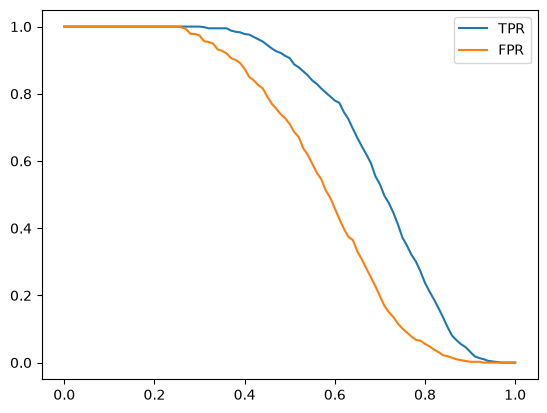

In [117]:
# Q3: Precision & Recall
# Now let's compute precision and recall for our model.

# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# For each threshold, compute precision and recall
# Plot them
# At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

scores = []

thresholds = np.linspace(0, 1, 101)
thresholds

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()


# from sklearn.metrics import roc_curve

# fpr, tpr, thresholds = roc_curve(y_val, y_pred)

In [118]:
# The random model
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [119]:
# The ideal model
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

NameError: name 'df_ideal' is not defined

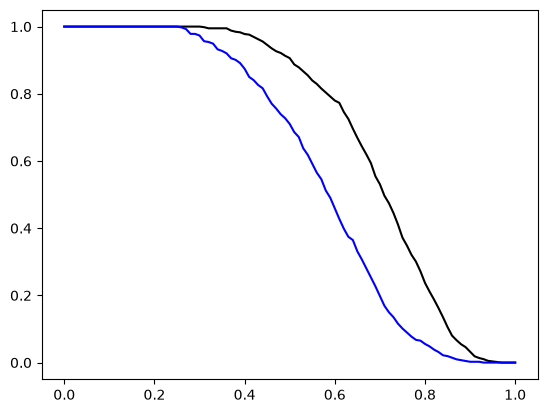

In [120]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

plt.legend()

Threshold: 0.0
F1 score, 0.7389659520807063
Threshold: 0.01
F1 score, 0.7389659520807063
Threshold: 0.02
F1 score, 0.7389659520807063
Threshold: 0.03
F1 score, 0.7389659520807063
Threshold: 0.04
F1 score, 0.7389659520807063
Threshold: 0.05
F1 score, 0.7389659520807063
Threshold: 0.06
F1 score, 0.7389659520807063
Threshold: 0.07
F1 score, 0.7389659520807063
Threshold: 0.08
F1 score, 0.7389659520807063
Threshold: 0.09
F1 score, 0.7389659520807063
Threshold: 0.1
F1 score, 0.7389659520807063
Threshold: 0.11
F1 score, 0.7389659520807063
Threshold: 0.12
F1 score, 0.7389659520807063
Threshold: 0.13
F1 score, 0.7389659520807063
Threshold: 0.14
F1 score, 0.7389659520807063
Threshold: 0.15
F1 score, 0.7389659520807063
Threshold: 0.16
F1 score, 0.7389659520807063
Threshold: 0.17
F1 score, 0.7389659520807063
Threshold: 0.18
F1 score, 0.7389659520807063
Threshold: 0.19
F1 score, 0.7389659520807063
Threshold: 0.2
F1 score, 0.7389659520807063
Threshold: 0.21
F1 score, 0.7389659520807063
Threshold: 0.

/tmp/ipykernel_43911/1782720740.py:21: RuntimeWarning: invalid value encountered in scalar divide
  p = tp / (tp + fp)


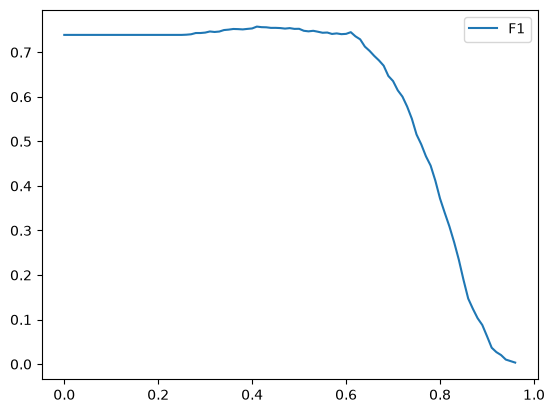

In [121]:
# Q4. F1 Score


scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    print(f"Threshold: {t}")
    p = tp / (tp + fp)
    # print(f"p{p}")
    r = tp / (tp + fn)
    f1 = 2*((p*r)/(p + r))
    print(f"F1 score, {f1}")
    
    scores.append((t, tp, fp, fn, tn, f1))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn','f1']
df_scores = pd.DataFrame(scores, columns=columns)

plt.plot(df_scores.threshold, df_scores['f1'], label='F1')
plt.legend()



# df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
# df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)


In [122]:
# Q5: Question 5: 5-Fold CV
# K-fold cross-validation
# The idea of k-fold cross-validation: split the full training dataset into k partitions (folds). Train the model on k-1 folds, 
# evaluate on the remaining one. Repeat k times, so every fold serves as the validation set once, and average the scores.

from sklearn.model_selection import KFold
KFold(n_splits=5, shuffle=True, random_state=1)

KFold(n_splits=5, random_state=1, shuffle=True)

In [131]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000) # Model for Q6
    # model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000) # Model for Q5
    model.fit(X_train, y_train)
    
    return dv, model

In [132]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [130]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.732 +- 0.007
C=0.01 0.732 +- 0.007
C=0.1 0.732 +- 0.007
C=0.5 0.732 +- 0.007
C=1 0.732 +- 0.007
C=5 0.732 +- 0.007
C=10 0.732 +- 0.007


In [133]:
# Q6: Question 6: Hyperparameter Tuning
# Now let's use 5-Fold cross-validation to find the best parameter C

# Iterate over the following C values: [0.000001, 0.001, 1]
# Initialize KFold with the same parameters as previously
# Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
# Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).


from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
